In [23]:
import pandas as pd
from sqlalchemy import create_engine
from urllib.parse import quote_plus
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import joblib

In [24]:
# SQL Server connection parameters
server = r"localhost\SQLEXPRESS"
database = "db_churn"

# Create SQL Server connection
connection_string = (
    f"DRIVER={{ODBC Driver 18 for SQL Server}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    f"Trusted_Connection=yes;"
    f"TrustServerCertificate=yes;"
)

engine = create_engine(
    "mssql+pyodbc:///?odbc_connect=" + quote_plus(connection_string)
)

# Import vw_ChurnData
df_churn = pd.read_sql(
    "SELECT * FROM dbo.vw_ChurnData",
    engine
)

# Import vw_JoinData
df_join = pd.read_sql(
    "SELECT * FROM dbo.vw_JoinData",
    engine
)

In [25]:
# Check the imported data
print("vw_ChurnData shape:", df_churn.shape)
print("vw_JoinData shape:", df_join.shape)

print("\nChurn Data:")
display(df_churn.head())

print("\nJoin Data:")
display(df_join.head())

vw_ChurnData shape: (6007, 32)
vw_JoinData shape: (411, 32)

Churn Data:


,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,CUST-00002,Male,63,No,Massachusetts,10,16,None,Yes,No,...,Credit Card,5105.0,20660.0,0.0,0,58734.0,265334.0,Stayed,Others,Others
1,CUST-00003,Female,51,Yes,Puducherry,8,31,Offer 4,Yes,No,...,Credit Card,2025.0,2080.0,0.0,0,31482.0,52282.0,Stayed,Others,Others
2,CUST-00004,Female,45,Yes,Illinois,15,1,None,Yes,Yes,...,Credit Card,950.0,300815.0,0.0,60,34122.0,340937.0,Stayed,Others,Others
3,CUST-00005,Female,59,No,Georgia,1,6,Offer 4,Yes,Yes,...,Bank Withdrawal,8005.0,134565.0,0.0,0,76432.0,210997.0,Stayed,Others,Others
4,CUST-00006,Female,31,Yes,California,0,26,Offer 4,Yes,No,...,Credit Card,951.0,8651.0,4325.0,0,4569.0,127875.0,Stayed,Others,Others



Join Data:


,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,CUST-00001,Male,54,No,Washington,6,2,None,Yes,No,...,Credit Card,191.0,5305.0,0.0,0,4896.0,10201.0,Joined,Others,Others
1,CUST-00009,Female,38,Yes,Arizona,6,12,None,Yes,No,...,Credit Card,2025.0,368.0,0.0,0,3166.0,6846.0,Joined,Others,Others
2,CUST-00023,Female,28,Yes,Tennessee,15,9,None,Yes,No,...,Bank Withdrawal,499.0,499.0,0.0,0,1493.0,6483.0,Joined,Others,Others
3,CUST-00036,Female,59,No,Nevada,1,2,Offer 5,Yes,Yes,...,Bank Withdrawal,543.0,543.0,0.0,10,3402.0,9832.0,Joined,Others,Others
4,CUST-00040,Female,72,Yes,Florida,7,17,None,No,No,...,Bank Withdrawal,3075.0,8285.0,0.0,0,0.0,8285.0,Joined,Others,Others


In [26]:
# Drop columns that won't be used for prediction
data = df_churn.drop(['Customer_ID', 'Churn_Category', 'Churn_Reason'], axis=1)

In [27]:
# List of columns to be label encoded

columns_to_encode = [

    'Gender', 'Married', 'State', 'Value_Deal', 'Phone_Service', 'Multiple_Lines',

    'Internet_Service', 'Internet_Type', 'Online_Security', 'Online_Backup',

    'Device_Protection_Plan', 'Premium_Support', 'Streaming_TV', 'Streaming_Movies',

    'Streaming_Music', 'Unlimited_Data', 'Contract', 'Paperless_Billing',

    'Payment_Method'

]

# Encode categorical variables except the target variable

label_encoders = {}

for column in columns_to_encode:

    label_encoders[column] = LabelEncoder()

    data[column] = label_encoders[column].fit_transform(data[column])


# Manually encode the target variable 'Customer_Status'

data['Customer_Status'] = data['Customer_Status'].map({'Stayed': 0, 'Churned': 1})


In [16]:
# Split data into features and target

X = data.drop('Customer_Status', axis=1)

y = data['Customer_Status']

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Confusion Matrix:
[[796  54]
 [138 214]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.94      0.89       850
           1       0.80      0.61      0.69       352

    accuracy                           0.84      1202
   macro avg       0.83      0.77      0.79      1202
weighted avg       0.84      0.84      0.83      1202



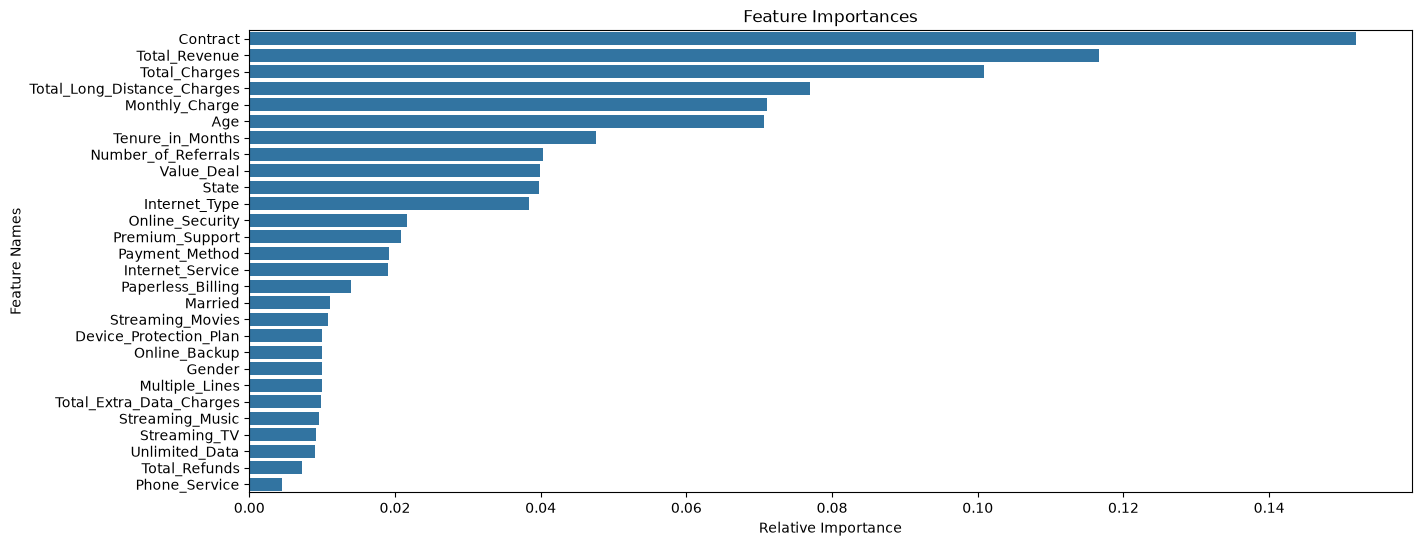

In [28]:
# Initialize the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

 

# Train the model

rf_model.fit(X_train, y_train)

 

# Make predictions

y_pred = rf_model.predict(X_test)

 

# Evaluate the model

print("Confusion Matrix:")

print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

 

# Feature Selection using Feature Importance

importances = rf_model.feature_importances_

indices = np.argsort(importances)[::-1]

 

# Plot the feature importances

plt.figure(figsize=(15, 6))

sns.barplot(x=importances[indices], y=X.columns[indices])

plt.title('Feature Importances')

plt.xlabel('Relative Importance')

plt.ylabel('Feature Names')

plt.show()

In [29]:
# Keep original data
original_data = df_join.copy()

# Prepare prediction dataset
new_data = df_join.drop([
    'Customer_ID',
    'Customer_Status',
    'Churn_Category',
    'Churn_Reason'
], axis=1)

# Encode categorical columns
for column in columns_to_encode:
    new_data[column] = label_encoders[column].transform(new_data[column])

# Predict
predictions = rf_model.predict(new_data)

# Add predictions
original_data['Customer_Status_Predicted'] = predictions

# Filter churned customers
churn_customers = original_data[
    original_data['Customer_Status_Predicted'] == 1
]

print(churn_customers.head())

  Customer_ID  Gender  Age Married      State  Number_of_Referrals  \
1  CUST-00009  Female   38     Yes    Arizona                    6   
2  CUST-00023  Female   28     Yes  Tennessee                   15   
3  CUST-00036  Female   59      No     Nevada                    1   
4  CUST-00040  Female   72     Yes    Florida                    7   
5  CUST-00046  Female   34     Yes   New York                    3   

   Tenure_in_Months Value_Deal Phone_Service Multiple_Lines  ...  \
1                12       None           Yes             No  ...   
2                 9       None           Yes             No  ...   
3                 2    Offer 5           Yes            Yes  ...   
4                17       None            No             No  ...   
5                22       None           Yes             No  ...   

  Monthly_Charge Total_Charges Total_Refunds Total_Extra_Data_Charges  \
1         2025.0         368.0           0.0                        0   
2          499.0        

In [30]:
print(original_data['Customer_Status_Predicted'].value_counts())

Customer_Status_Predicted
1    316
0     95
Name: count, dtype: int64


In [32]:
# Save the results
original_data.to_csv(r"C:\Users\karim\OneDrive\Desktop\power BI projects\Customer Churn Analysis\Predictions.csv", index=False)